EDA Project

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

Step 1 : Data Collection and Loading

In [2]:
df=pd.read_csv("Churn_Modelling.csv")

Step 2 : Understanding Dataset Structure

In [3]:
df.head()

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


The Dataset has a Target Column named Exited which tells if the customer has left the bank or not.

In [4]:
df.tail()

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
9995,9996,15606229,Obijiaku,771,France,Male,39,5,0.00,2,1,0,96270.64,0
9996,9997,15569892,Johnstone,516,France,Male,35,10,57369.61,1,1,1,101699.77,0
9997,9998,15584532,Liu,709,France,Female,36,7,0.00,1,0,1,42085.58,1
9998,9999,15682355,Sabbatini,772,Germany,Male,42,3,75075.31,2,1,0,92888.52,1
9999,10000,15628319,Walker,792,France,Female,28,4,130142.79,1,1,0,38190.78,0


In [5]:
df.sample(5)

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
858,859,15686137,Barry,456,Spain,Male,32,9,147506.25,1,1,1,135399.21,0
7580,7581,15781975,Rees,708,France,Male,34,3,0.00,1,0,1,121457.88,1
8749,8750,15701238,Chia,683,France,Male,47,1,0.00,2,1,0,148989.15,0
149,150,15794413,Harris,416,France,Male,32,0,0.00,2,0,1,878.87,0
2091,2092,15672945,Parkes,661,France,Female,37,5,136425.18,1,1,0,81102.81,0


In [6]:
df.shape

(10000, 14)

In [7]:
df.columns

Index(['RowNumber', 'CustomerId', 'Surname', 'CreditScore', 'Geography',
       'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard',
       'IsActiveMember', 'EstimatedSalary', 'Exited'],
      dtype='str')

In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  str    
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  str    
 5   Gender           10000 non-null  str    
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), str(3)
memory usage: 1.2 MB


In [9]:
df.dtypes

RowNumber            int64
CustomerId           int64
Surname                str
CreditScore          int64
Geography              str
Gender                 str
Age                  int64
Tenure               int64
Balance            float64
NumOfProducts        int64
HasCrCard            int64
IsActiveMember       int64
EstimatedSalary    float64
Exited               int64
dtype: object

Step 3: Data Quality Assessment

In [10]:
df.isnull().sum()

RowNumber          0
CustomerId         0
Surname            0
CreditScore        0
Geography          0
Gender             0
Age                0
Tenure             0
Balance            0
NumOfProducts      0
HasCrCard          0
IsActiveMember     0
EstimatedSalary    0
Exited             0
dtype: int64

In [11]:
print("Percentage of Null Values: ",sum(df.isnull().mean()*100))

Percentage of Null Values:  0.0


In [12]:
df.duplicated().sum()

np.int64(0)

Dataset does not have any null and duplicate values.

In [13]:
df["Geography"].unique()

<ArrowStringArray>
['France', 'Spain', 'Germany']
Length: 3, dtype: str

In [14]:
df["Gender"].value_counts()

Gender
Male      5457
Female    4543
Name: count, dtype: int64

In [15]:
df["Tenure"].unique()

array([ 2,  1,  8,  7,  4,  6,  3, 10,  5,  9,  0])

In [16]:
df["NumOfProducts"].unique()

array([1, 3, 2, 4])

In [17]:
df["HasCrCard"].unique()

array([1, 0])

In [18]:
df["IsActiveMember"].unique()

array([1, 0])

In [19]:
df["Exited"].unique()

array([1, 0])

In [20]:
df.dtypes

RowNumber            int64
CustomerId           int64
Surname                str
CreditScore          int64
Geography              str
Gender                 str
Age                  int64
Tenure               int64
Balance            float64
NumOfProducts        int64
HasCrCard            int64
IsActiveMember       int64
EstimatedSalary    float64
Exited               int64
dtype: object

The Three Columns "HasCrCard","IsActiveMember","Exited" are binary columns mentioned as int64

Step 4: Data Cleaning and Handling Missing Values

In [21]:
df.head()

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


The Dataset does not contain any null and duplicated values

Step 5: Descriptive Statistical Analysis

In [22]:
df.describe(include="number")

,RowNumber,CustomerId,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
count,10000.00000,1.000000e+04,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000,10000.000000,10000.000000,10000.000000
mean,5000.50000,1.569094e+07,650.528800,38.921800,5.012800,76485.889288,1.530200,0.70550,0.515100,100090.239881,0.203700
std,2886.89568,7.193619e+04,96.653299,10.487806,2.892174,62397.405202,0.581654,0.45584,0.499797,57510.492818,0.402769
min,1.00000,1.556570e+07,350.000000,18.000000,0.000000,0.000000,1.000000,0.00000,0.000000,11.580000,0.000000
25%,2500.75000,1.562853e+07,584.000000,32.000000,3.000000,0.000000,1.000000,0.00000,0.000000,51002.110000,0.000000
50%,5000.50000,1.569074e+07,652.000000,37.000000,5.000000,97198.540000,1.000000,1.00000,1.000000,100193.915000,0.000000
75%,7500.25000,1.575323e+07,718.000000,44.000000,7.000000,127644.240000,2.000000,1.00000,1.000000,149388.247500,0.000000
max,10000.00000,1.581569e+07,850.000000,92.000000,10.000000,250898.090000,4.000000,1.00000,1.000000,199992.480000,1.000000


In [23]:
df.describe(include="str")

,Surname,Geography,Gender
count,10000,10000,10000
unique,2932,3,2
top,Smith,France,Male
freq,32,5014,5457


Step 6: Univariate Analysis

1.Numeric Variables

In [24]:
# Customers with minimum credit score 
df[df["CreditScore"]>=700].head(3)

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0
6,7,15592531,Bartlett,822,France,Male,50,7,0.00,2,1,1,10062.80,0
19,20,15568982,Hao,726,France,Female,24,6,0.00,2,1,1,54724.03,0


In [25]:
# Customers with age greater than 50
df[df["Age"]>=50].head(3)

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
6,7,15592531,Bartlett,822,France,Male,50,7,0.00,2,1,1,10062.80,0
16,17,15737452,Romeo,653,Germany,Male,58,1,132602.88,1,1,0,5097.67,1
41,42,15738148,Clarke,465,France,Female,51,8,122522.32,1,0,0,181297.65,1


In [26]:
# Customer with maximum Estimated Salary
df[df["EstimatedSalary"]==df["EstimatedSalary"].max()]

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
6646,6647,15662021,Lucciano,685,Spain,Female,42,2,0.0,2,0,0,199992.48,0


In [27]:
# The Customers who left the bank
df[df["Exited"]==1].head(2)

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.0,1,1,1,101348.88,1
2,3,15619304,Onio,502,France,Female,42,8,159660.8,3,1,0,113931.57,1


Plotting Numerical Variables

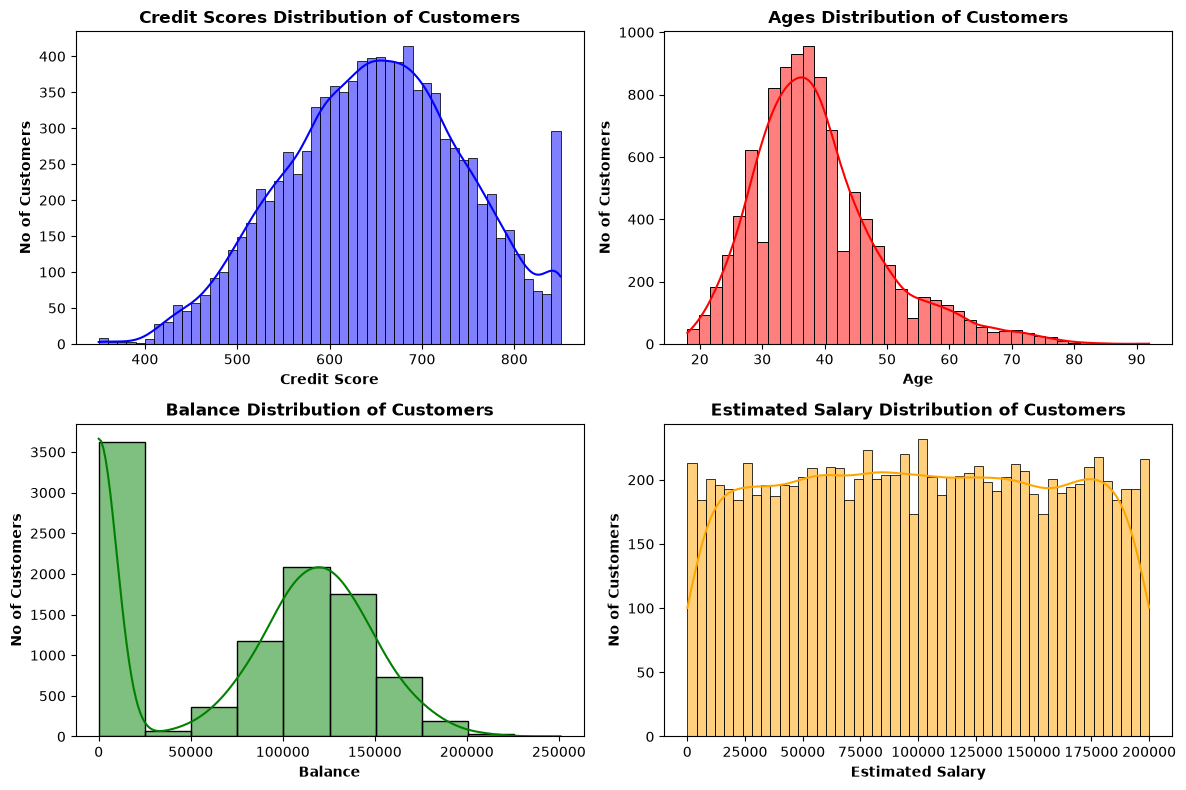

In [28]:
# Histogram

plt.figure(figsize=(12,8))

plt.subplot(2,2,1)
sns.histplot(data=df,x="CreditScore",kde=True,bins=50,color="blue")
plt.title("Credit Scores Distribution of Customers",fontweight="bold")
plt.xlabel("Credit Score",fontweight="bold")
plt.ylabel("No of Customers",fontweight="bold")

plt.subplot(2,2,2)
sns.histplot(data=df,x="Age",kde=True,bins=40,color="red")
plt.title("Ages Distribution of Customers",fontweight="bold")
plt.xlabel("Age",fontweight="bold")
plt.ylabel("No of Customers",fontweight="bold")

plt.subplot(2,2,3)
sns.histplot(data=df,x="Balance",kde=True,bins=10,color="green")
plt.title("Balance Distribution of Customers",fontweight="bold")
plt.xlabel("Balance",fontweight="bold")
plt.ylabel("No of Customers",fontweight="bold")

plt.subplot(2,2,4)
sns.histplot(data=df,x="EstimatedSalary",kde=True,bins=50,color="orange")
plt.title("Estimated Salary Distribution of Customers",fontweight="bold")
plt.xlabel("Estimated Salary",fontweight="bold")
plt.ylabel("No of Customers",fontweight="bold")

plt.tight_layout()
plt.show()

1. Credit Scores of Customers are approximately normaly Distributed  
2. Ages of Customers are Right Skewed  
3. Most Customers have zero balance with with second peak noramlly distributed  
4. Estimated Salary of Customers are uniformily distribured

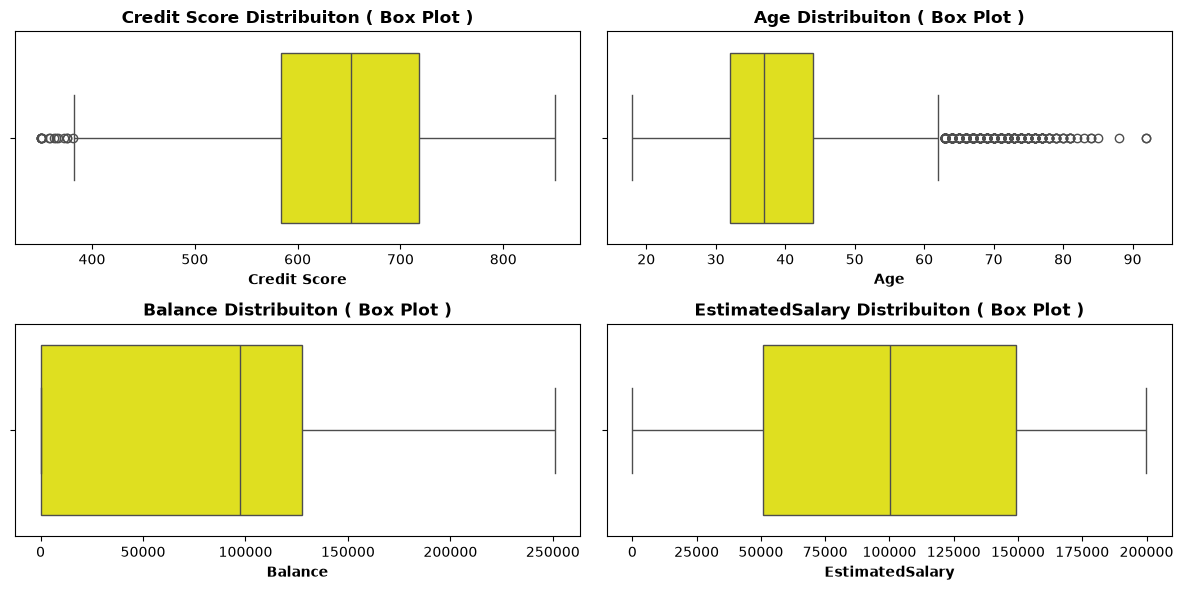

In [29]:
# Box Plot

plt.figure(figsize=(12,6))

plt.subplot(2,2,1)
sns.boxplot(data=df,x="CreditScore",color="yellow")
plt.title("Credit Score Distribuiton ( Box Plot )",fontweight="bold")
plt.xlabel("Credit Score",fontweight="bold")

plt.subplot(2,2,2)
sns.boxplot(data=df,x="Age",color="yellow")
plt.title("Age Distribuiton ( Box Plot )",fontweight="bold")
plt.xlabel("Age",fontweight="bold")

plt.subplot(2,2,3)
sns.boxplot(data=df,x="Balance",color="yellow")
plt.title("Balance Distribuiton ( Box Plot )",fontweight="bold")
plt.xlabel("Balance",fontweight="bold")

plt.subplot(2,2,4)
sns.boxplot(data=df,x="EstimatedSalary",color="yellow")
plt.title("EstimatedSalary Distribuiton ( Box Plot )",fontweight="bold")
plt.xlabel("EstimatedSalary",fontweight="bold")

plt.tight_layout()
plt.show()

There are outliers present in Credit Score and Age Columns  


2. Categorical Variables

In [30]:
df["Geography"].unique()

<ArrowStringArray>
['France', 'Spain', 'Germany']
Length: 3, dtype: str

In [31]:
# Customers from Spain 
df[df["Geography"]=="Spain"].head(3)

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0
5,6,15574012,Chu,645,Spain,Male,44,8,113755.78,2,1,0,149756.71,1


In [32]:
# Male Customers
df[df["Gender"]=="Male"].head(2)

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
5,6,15574012,Chu,645,Spain,Male,44,8,113755.78,2,1,0,149756.71,1
6,7,15592531,Bartlett,822,France,Male,50,7,0.00,2,1,1,10062.80,0


In [33]:
# Country from which most customers are from 
df["Geography"].mode()[0]

'France'

In [34]:
# Percentage of Customers from each country
geography=df["Geography"].value_counts()/len(df)*100

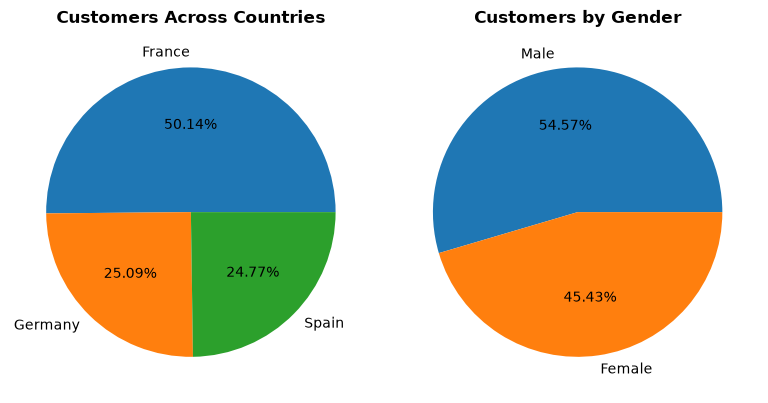

In [35]:
plt.figure(figsize=(8,4))

plt.subplot(1,2,1)
plt.pie(df["Geography"].value_counts(),labels=df["Geography"].value_counts().index,autopct="%1.2f%%")
plt.title("Customers Across Countries",fontweight="bold")

plt.subplot(1,2,2)
plt.pie(df["Gender"].value_counts(),labels=df["Gender"].value_counts().index,autopct="%1.2f%%")
plt.title("Customers by Gender",fontweight="bold")

plt.tight_layout()
plt.show()

From the pie charts above it is clear that most customers are from the country France   
By Gender Male Customers have slight increase over Female

Step 7: Bivariate and Multivariate Analysis

1. Numerical vs. numerical

In [36]:
# Customers with Credit Score greater than 700 who are active
df[(df["CreditScore"]>=700) & (df["IsActiveMember"]==1)].head(2)

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.1,0
6,7,15592531,Bartlett,822,France,Male,50,7,0.00,2,1,1,10062.8,0


In [37]:
# Customers who are Active but closed their account in the bank
df[(df["IsActiveMember"]==1) & (df["Exited"]==1)].head(2)

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
46,47,15602280,Martin,829,Germany,Female,27,9,112045.67,1,1,1,119708.21,1


In [38]:
# Average Age of Employees who are currently active and has an existing bank account
df[(df["IsActiveMember"]==1) & (df["Exited"]==0)]["Age"].agg("mean")

np.float64(38.96399456521739)

In [39]:
# Customers with the maximum no of bank products who are currently active and has existing bank account
max_no_of_products=df[(df["IsActiveMember"]==1) & (df["Exited"]==0)]
max_no_of_products[max_no_of_products["NumOfProducts"]==max_no_of_products["NumOfProducts"].max()].head(2)

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
549,550,15600651,Ijendu,749,France,Male,24,1,0.0,3,1,1,47911.03,0
569,570,15706647,Jordan,761,France,Male,31,7,0.0,3,1,1,166698.18,0


In [40]:
# Average Credit Score of Customers who has an account for more than 5 years at the bank
df[df["Tenure"]>=5]["CreditScore"].mean()

np.float64(650.125317835089)

In [41]:
# Credit Score Across different years at bank
df.groupby("Tenure")["CreditScore"].agg(["mean","max","min"])

,mean,max,min
Tenure,,,
0,652.043584,850,350
1,648.806763,850,350
2,652.832061,850,399
3,650.530228,850,350
4,651.502528,850,351
5,650.527668,850,395
6,647.380558,850,359
7,649.606031,850,373
8,647.749268,850,358


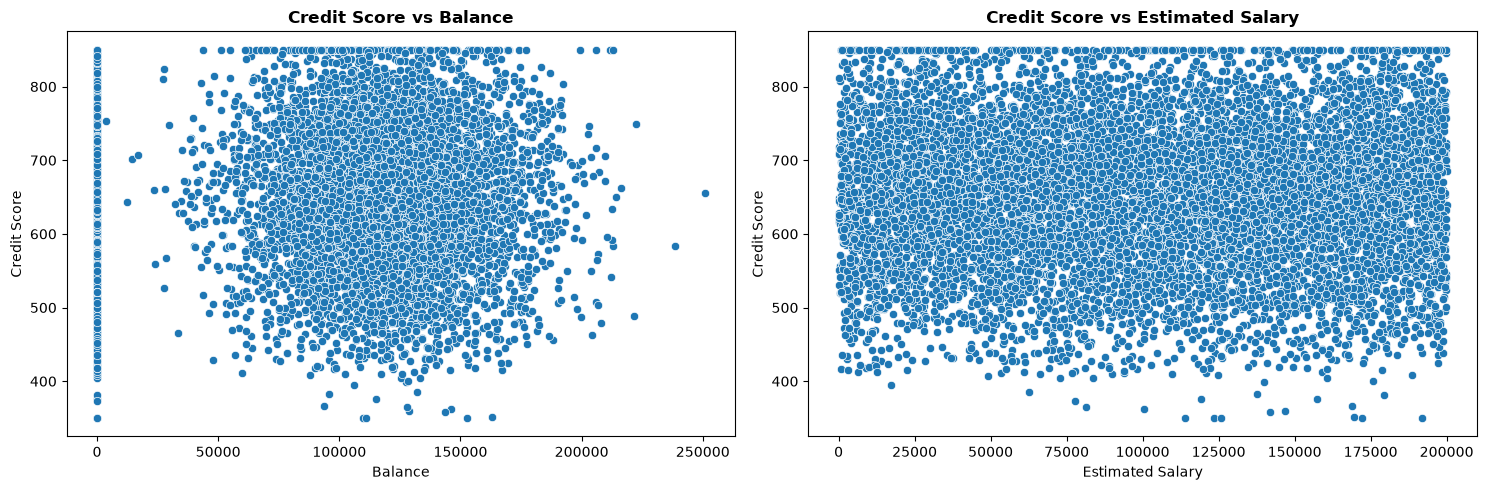

In [42]:
# Scatter Plot
plt.figure(figsize=(15,5))

plt.subplot(1,2,1)
sns.scatterplot(data=df,x="Balance",y="CreditScore")
plt.title("Credit Score vs Balance",fontweight="bold")
plt.ylabel("Credit Score")
plt.xlabel("Balance")

plt.subplot(1,2,2)
sns.scatterplot(data=df,x="EstimatedSalary",y="CreditScore")
plt.title("Credit Score vs Estimated Salary",fontweight="bold")
plt.ylabel("Credit Score")
plt.xlabel("Estimated Salary")

plt.tight_layout()
plt.show()

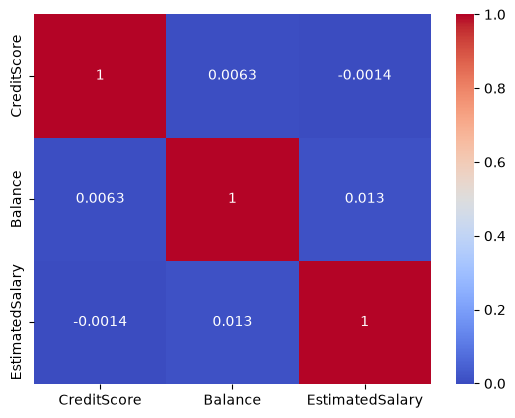

In [43]:
# Heatmap

corr=df[["CreditScore", "Balance", "EstimatedSalary"]].corr()

sns.heatmap(corr,annot=True,cmap="coolwarm")
plt.show()

Credit Score is not showing any strong relation with Balance  
Credit Score is showing is litte affect by Estimated Salary

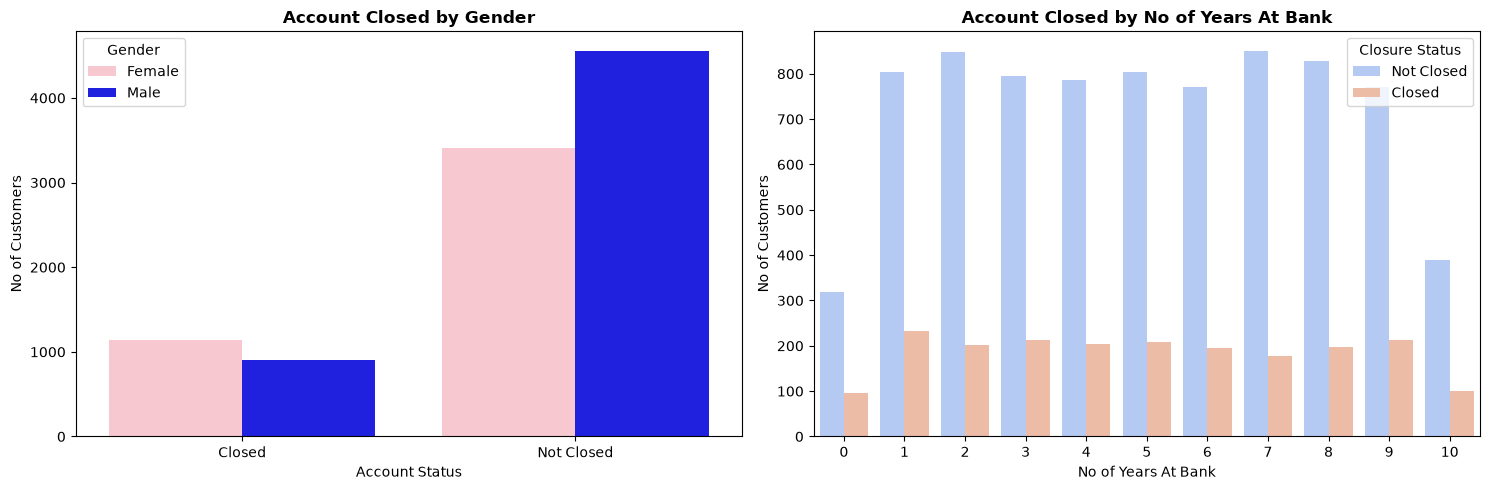

In [44]:
plt.figure(figsize=(15,5))

plt.subplot(1,2,1)
sns.countplot(data=df,x=df["Exited"].map({0:"Not Closed",1:"Closed"}),hue="Gender",palette={"Male":"blue","Female":"pink"})
plt.title("Account Closed by Gender",fontweight="bold")
plt.xlabel("Account Status")
plt.ylabel("No of Customers")

plt.subplot(1,2,2)
sns.countplot(data=df,x="Tenure",hue=df["Exited"].map({0:"Not Closed",1:"Closed"}),palette="coolwarm")
plt.title("Account Closed by No of Years At Bank",fontweight="bold")
plt.legend(title="Closure Status")
plt.xlabel("No of Years At Bank")
plt.ylabel("No of Customers")

plt.tight_layout()
plt.show()

2. Categorical vs. categorical

In [45]:
# Female Customers from Spain 
df[(df["Gender"]=="Female") & (df["Geography"]=="Spain")].head(2)

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


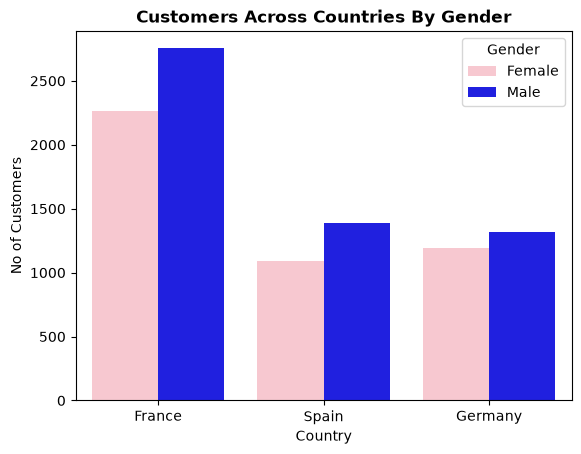

In [46]:
sns.countplot(data=df,x="Geography",hue="Gender",palette={"Male":"blue","Female":"pink"})
plt.title("Customers Across Countries By Gender",fontweight="bold")
plt.xlabel("Country")
plt.ylabel("No of Customers")
plt.show()

Higher Number of Male and Female Customers are from France

3.  Categorical vs. numerical

In [47]:
# Name of Customers whose age is greater and 50, country is France, Estimated Salary greater than 50000 and still has an account in the bank
df[(df["Age"]>=50) & (df["Geography"]=="France") & (df["EstimatedSalary"]>=5000) & (df["Exited"]==0)]["Surname"]

6        Bartlett
42        Osborne
59      Velazquez
76             Hu
158       Maclean
          ...    
9751          Yen
9765       Thomas
9894        Vagin
9909     Endrizzi
9936        Parks
Name: Surname, Length: 375, dtype: str

In [48]:
# Average Salary of Male Customers from Germany, between ages of 30 and 40 who has account in bank between 5-7 years

df[((df["Gender"]=="Male") & (df["Age"]>=30) & (df["Age"]<=40)) & ((df["Tenure"]>=5) & (df["Tenure"]<=7)) & (df["Geography"]=="Germany")]["EstimatedSalary"].mean()

np.float64(104248.49676300577)

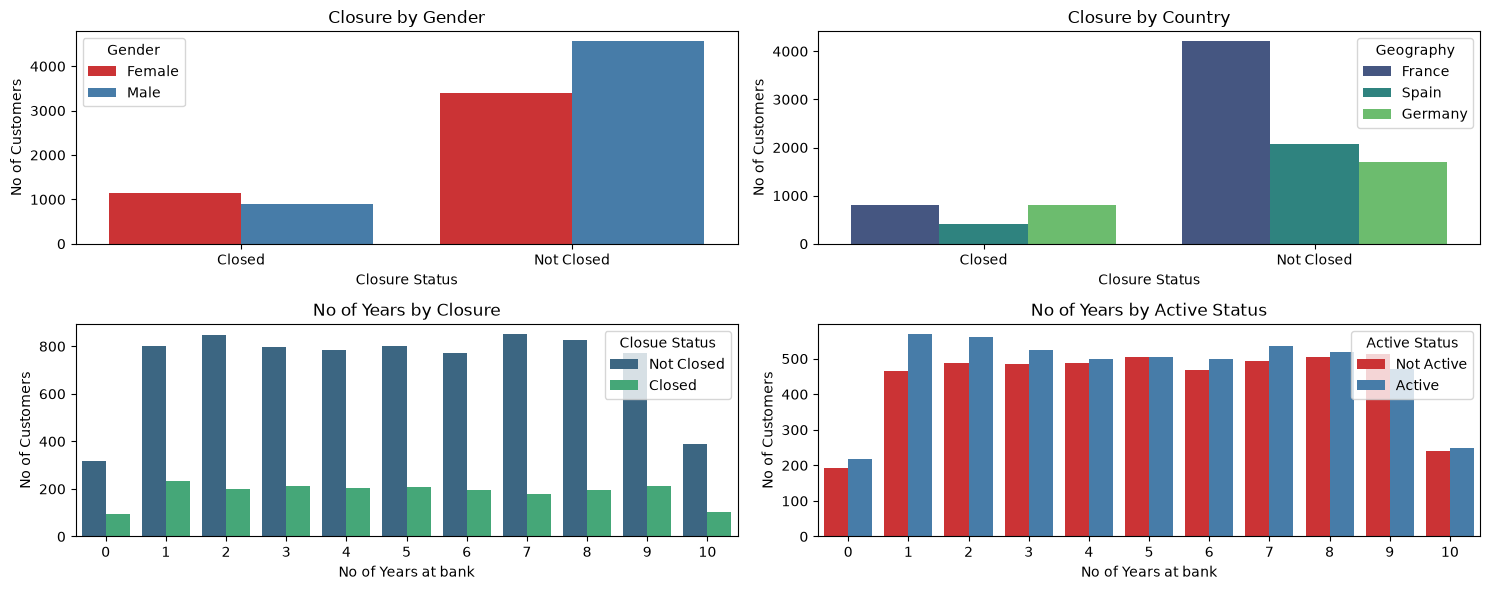

In [49]:
plt.figure(figsize=(15,6))

plt.subplot(2,2,1)
sns.countplot(data=df,x=df["Exited"].map({0:"Not Closed",1:"Closed"}),hue="Gender",palette="Set1")
plt.title("Closure by Gender")
plt.xlabel("Closure Status")
plt.ylabel("No of Customers")

plt.subplot(2,2,2)
sns.countplot(data=df,x=df["Exited"].map({0:"Not Closed",1:"Closed"}),hue="Geography",palette="viridis")
plt.title("Closure by Country")
plt.xlabel("Closure Status")
plt.ylabel("No of Customers")

plt.subplot(2,2,3)
sns.countplot(data=df,x="Tenure",hue="Exited",palette="viridis")
plt.title("No of Years by Closure")
plt.xlabel("No of Years at bank")
plt.ylabel("No of Customers")
plt.legend(title="Closue Status",labels=["Not Closed","Closed"])

plt.subplot(2,2,4)
sns.countplot(data=df,x="Tenure",hue="IsActiveMember",palette="Set1")
plt.title("No of Years by Active Status")
plt.xlabel("No of Years at bank")
plt.ylabel("No of Customers")
plt.legend(title="Active Status",labels=["Not Active","Active"])

plt.tight_layout()
plt.show()

More Customers who have closed their account are male and are from France  
Most Customers close their account between 1-9 years at the bank 


In [50]:
Exited=df[df["Exited"]==1]
Not_Exited=df[df["Exited"]==0]

In [51]:
Exited_Line=Exited.groupby("Tenure")["Exited"].count().reset_index()
Not_Exited_line=Not_Exited.groupby("Tenure")["Exited"].count().reset_index()

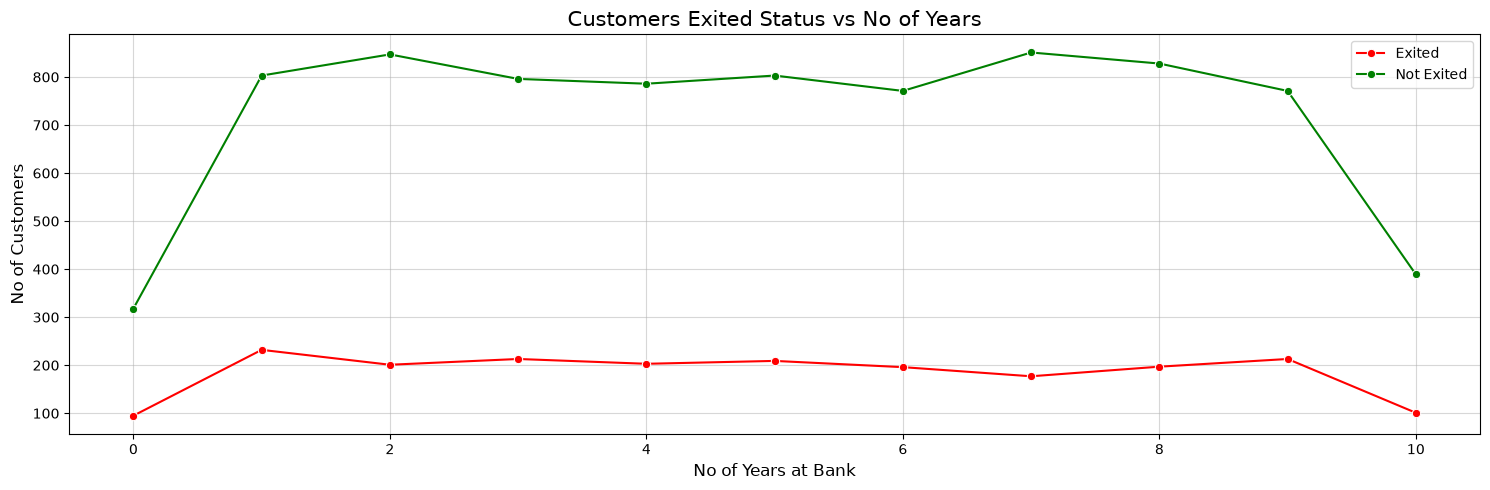

In [52]:
plt.figure(figsize=(15,5))

sns.lineplot(data=Exited_Line,x="Tenure",y="Exited",marker="o",color="red",label="Exited")

sns.lineplot(data=Not_Exited_line,x="Tenure",y="Exited",marker="o",color="green",label="Not Exited")

plt.grid(True,alpha=0.5)
plt.title("Customers Exited Status vs No of Years",fontsize=15)
plt.xlabel("No of Years at Bank",fontsize=12)
plt.ylabel("No of Customers",fontsize=12)

plt.tight_layout()
plt.show()

In [53]:
churn_rate=df.groupby("Tenure")["Exited"].mean().reset_index()
churn_rate["Exited"]=churn_rate["Exited"]*100

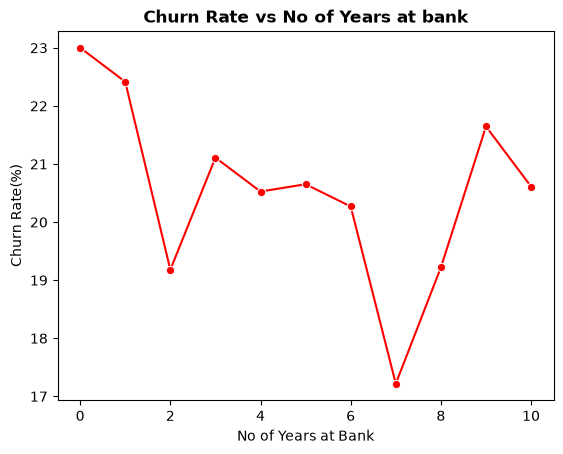

In [54]:
sns.lineplot(data=churn_rate,x="Tenure",y="Exited",color="red",marker="o")
plt.title("Churn Rate vs No of Years at bank",fontweight="bold")
plt.xlabel("No of Years at Bank")
plt.ylabel("Churn Rate(%)")
plt.show()

In [55]:
country_churn=df.groupby("Geography")["Exited"].mean().reset_index()
country_churn["Churn Rate"]=country_churn["Exited"]*100

gender_churn=df.groupby("Gender")["Exited"].mean().reset_index()
gender_churn["Churn Rate"]=gender_churn["Exited"]*100

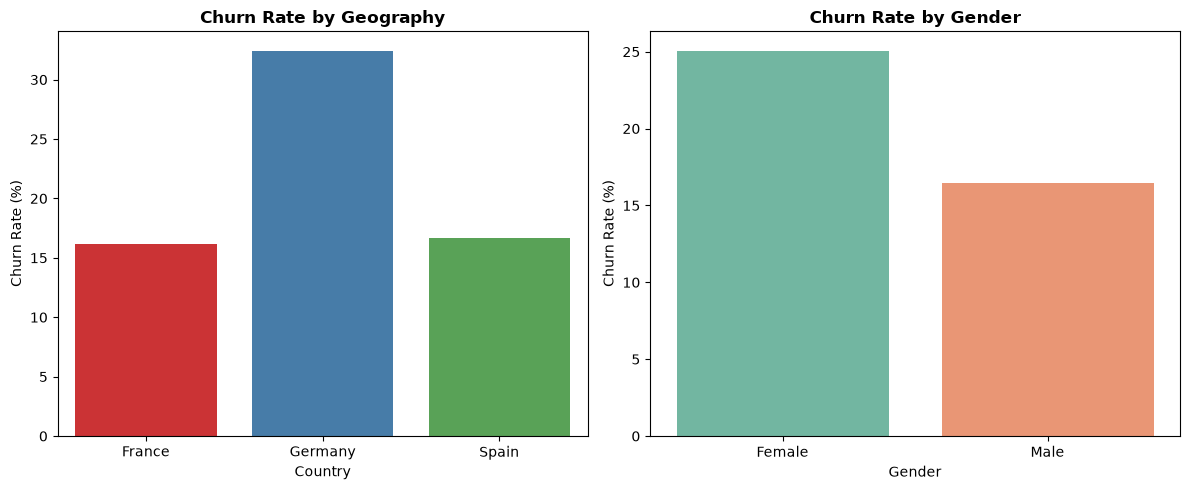

In [56]:
plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
sns.barplot(data=country_churn,x="Geography",y="Churn Rate",hue="Geography",palette="Set1")
plt.title("Churn Rate by Geography",fontweight="bold")
plt.ylabel("Churn Rate (%)")
plt.xlabel("Country")

plt.subplot(1,2,2)
sns.barplot(data=gender_churn,x="Gender",y="Churn Rate",hue="Gender",palette="Set2")
plt.title("Churn Rate by Gender",fontweight="bold")
plt.ylabel("Churn Rate (%)")
plt.xlabel("Gender")

plt.tight_layout()
plt.show()

Outliers Detection and Removal

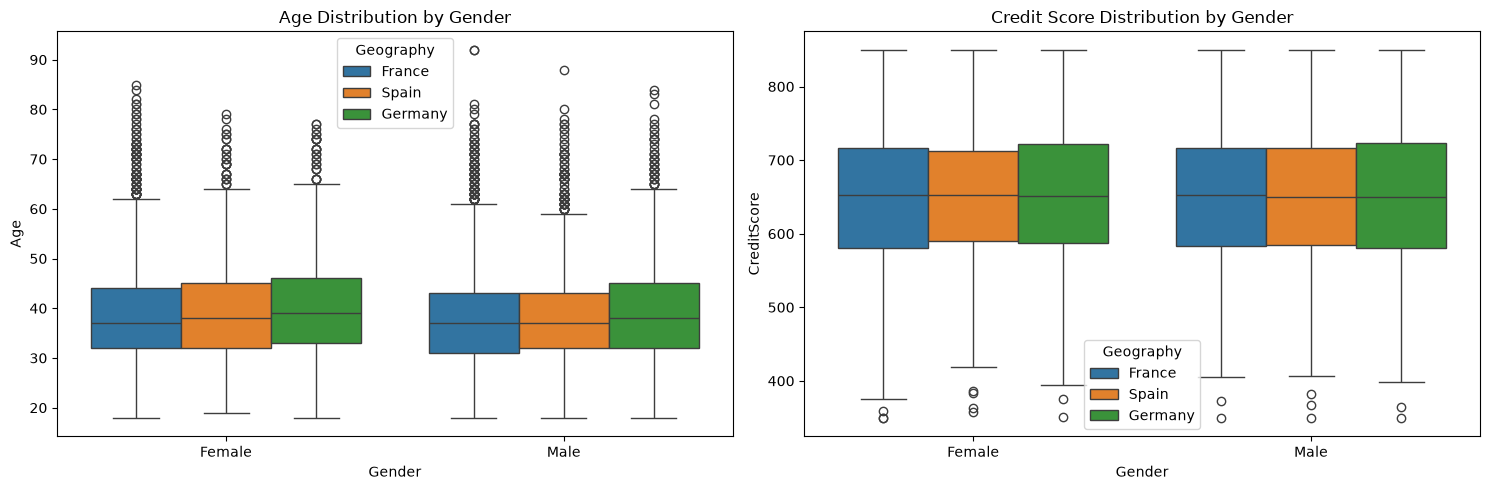

In [57]:
plt.figure(figsize=(15, 5))

plt.subplot(1,2,1)
sns.boxplot(data=df,x="Gender",y="Age",hue="Geography")
plt.title("Age Distribution by Gender")

plt.subplot(1,2,2)
sns.boxplot(data=df,x="Gender",y="CreditScore",hue="Geography")
plt.title("Credit Score Distribution by Gender")

plt.tight_layout()
plt.show()


Higher Number of Outliers are present in Age and a small amount in CreditScore

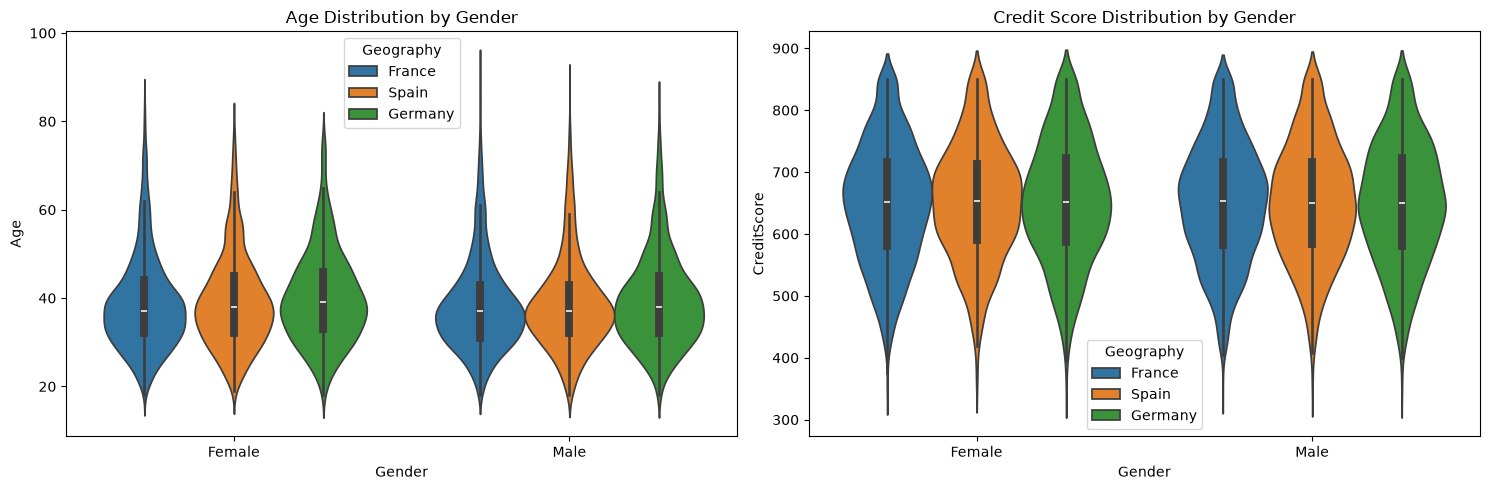

In [62]:
plt.figure(figsize=(15, 5))

plt.subplot(1,2,1)
sns.violinplot(data=df,x="Gender",y="Age",hue="Geography")
plt.title("Age Distribution by Gender")

plt.subplot(1,2,2)
sns.violinplot(data=df,x="Gender",y="CreditScore",hue="Geography")
plt.title("Credit Score Distribution by Gender")

plt.tight_layout()
plt.show()


Outliers Removal by IQR

In [58]:
def remove_outliers(df,col,group_col_1,group_col_2):
    
    group=df.groupby([group_col_1,group_col_2])[col]
    
    q1=group.transform(lambda x:x.quantile(0.25))
    q3=group.transform(lambda x:x.quantile(0.75))
    
    iqr=q3-q1
    
    lower_bound=q1-1.5*iqr
    upper_bound=q3+1.5*iqr
    
    return df[df[col].between(lower_bound,upper_bound)].reset_index(drop=True)

In [59]:
age_clean=remove_outliers(df,"Age","Gender","Geography")
credit_clean=remove_outliers(df,"CreditScore","Gender","Geography")

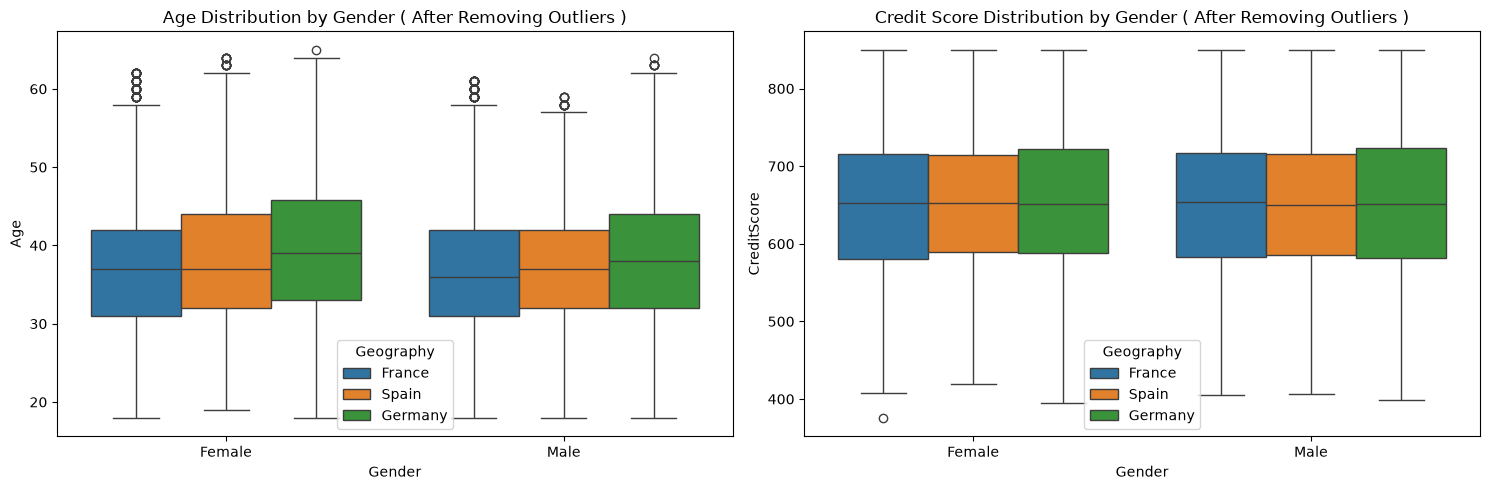

In [60]:
plt.figure(figsize=(15, 5))

plt.subplot(1,2,1)
sns.boxplot(data=age_clean,x="Gender",y="Age",hue="Geography")
plt.title("Age Distribution by Gender ( After Removing Outliers )")

plt.subplot(1,2,2)
sns.boxplot(data=credit_clean,x="Gender",y="CreditScore",hue="Geography")
plt.title("Credit Score Distribution by Gender ( After Removing Outliers )")

plt.tight_layout()
plt.show()

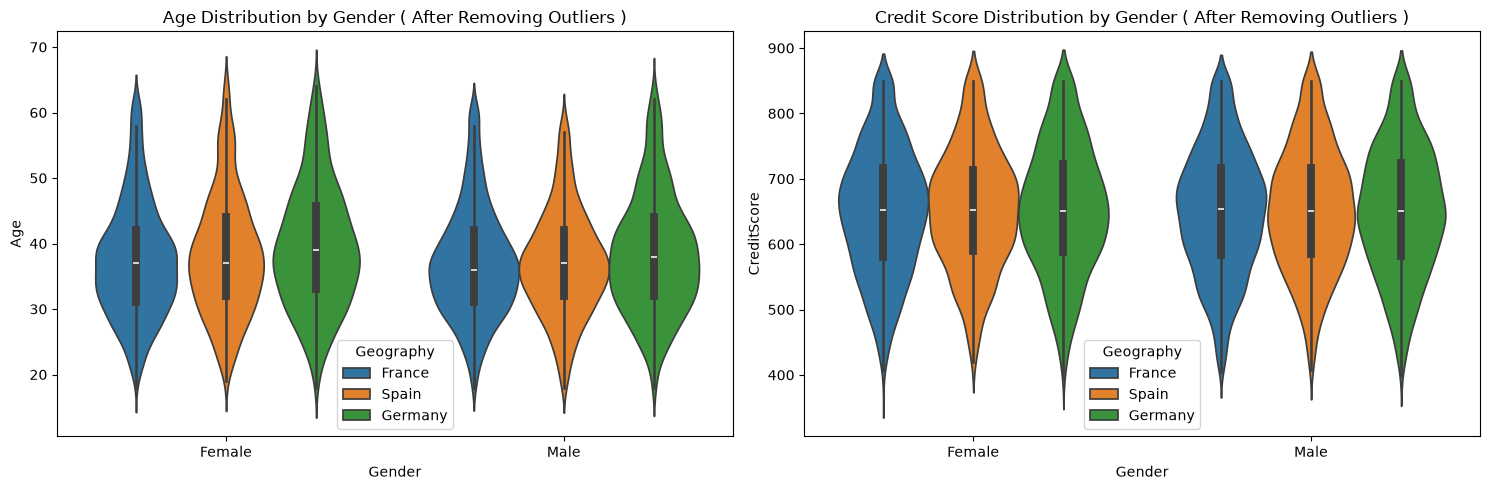

In [61]:
plt.figure(figsize=(15, 5))

plt.subplot(1,2,1)
sns.violinplot(data=age_clean,x="Gender",y="Age",hue="Geography")
plt.title("Age Distribution by Gender ( After Removing Outliers )")

plt.subplot(1,2,2)
sns.violinplot(data=credit_clean,x="Gender",y="CreditScore",hue="Geography")
plt.title("Credit Score Distribution by Gender ( After Removing Outliers )")

plt.tight_layout()
plt.show()